# 2. Exploración

Qué separa a los nuevos de los usados y qué se puede usar para predecir.

In [1]:
import sys
import warnings

sys.path.insert(0, "..")  # Los módulos están en la raíz del proyecto
warnings.filterwarnings("ignore")
%matplotlib inline

import re
import textwrap
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

import datos
import modelo
import pruebas

train, test = datos.construir(*datos.cargar_train_test())
train["y"] = modelo.y_binario(train)  # 1 si es usado
tasa_global = train["y"].mean()

## Funciones para graficar

Casi todos los gráficos muestran la tasa de usados contra alguna variable. La línea punteada es la tasa de usados de todo train. Las barras rojas quedan por encima y las azules por debajo.

In [2]:
COLOR_USADO, COLOR_NUEVO, COLOR_NEUTRO = "#c0392b", "#2471a3", "#7f8c8d"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "figure.constrained_layout.use": True})  # Acomoda solo el espacio entre gráficos


def tasa(mascara):
    """Tasa de usados entre los items que cumplen la condición."""
    return train.loc[mascara, "y"].mean()


def cifras(valores):
    """Tabla chica con las cifras que comenta el texto de abajo."""
    return pd.DataFrame({"valor": valores})


def linea_global(ax, horizontal=False):
    dibujar = ax.axvline if horizontal else ax.axhline
    dibujar(tasa_global, color=COLOR_NEUTRO, ls="--", lw=1, label=f"global ({tasa_global:.2f})")


def etiqueta(nivel):
    """Nombre legible de un nivel, partido en renglones si es largo."""
    texto = {"": "(vacío)", "nan": "(sin dato)"}.get(str(nivel), str(nivel)).replace("|", " + ")
    return textwrap.fill(texto, 24)


def tasa_por_categoria(df, columna, ax, top=12, min_n=30, titulo=None, por_tasa=True):
    """Barras con la tasa de usados de cada nivel y cuántos items tiene.

    Con por_tasa=False respeta el orden natural de los niveles, para variables como cantidades o tramos.
    """
    por_nivel = df.groupby(columna, dropna=False, observed=True)["y"].agg(["mean", "size"])
    por_nivel = por_nivel[por_nivel["size"] >= min_n].sort_values("size", ascending=False).head(top)
    # barh dibuja de abajo hacia arriba, así que el primer nivel natural va al final
    por_nivel = por_nivel.sort_values("mean") if por_tasa else por_nivel.sort_index(ascending=False)
    etiquetas = [etiqueta(nivel) for nivel in por_nivel.index]
    colores = [COLOR_USADO if t > tasa_global else COLOR_NUEVO for t in por_nivel["mean"]]
    ax.barh(etiquetas, por_nivel["mean"], color=colores, alpha=0.85)
    for i, (t, n) in enumerate(zip(por_nivel["mean"], por_nivel["size"])):
        ax.text(min(t + 0.01, 0.9), i, f"n={n:,}", va="center", fontsize=8)
    linea_global(ax, horizontal=True)
    ax.set(xlim=(0, 1), xlabel="tasa de usados", title=titulo or columna)


def tasa_por_tramos(df, columna, ax, tramos=10, titulo=None, log=False):
    """Tasa de usados por cuantiles de una variable numérica."""
    cortes = pd.qcut(df[columna], tramos, duplicates="drop")
    tasas = df.groupby(cortes, observed=True)["y"].mean()
    medianas = df.groupby(cortes, observed=True)[columna].median()
    ax.plot(medianas, tasas, marker="o", color=COLOR_USADO)
    linea_global(ax)
    if log:
        ax.set_xscale("symlog")
    ax.set(ylim=(0, 1), xlabel=f"{columna} (mediana del tramo)", ylabel="tasa de usados",
           title=titulo or columna)


def tasa_por_cruce(df, grupo, division, ax, nombres, titulo=None, min_n=20):
    """Tasa de usados por nivel de `grupo`, con una barra para cada valor de `division`."""
    tabla = df.groupby([grupo, division], observed=True)["y"].agg(["mean", "size"]).unstack(division)
    tasas = tabla["mean"].where(tabla["size"] >= min_n).dropna(how="all")
    orden = df[df[grupo].isin(tasas.index)].groupby(grupo, observed=True)["y"].mean().sort_values().index
    tasas = tasas.loc[orden]
    posiciones = np.arange(len(tasas))
    for k, (valor, color) in enumerate(zip(tasas.columns, ["#34495e", "#e67e22"])):
        desplazadas = posiciones + (k - 0.5) * 0.4
        ax.barh(desplazadas, tasas[valor], height=0.4, color=color, label=nombres[valor])
        for altura, t, n in zip(desplazadas, tasas[valor], tabla["size"].loc[orden, valor]):
            if not np.isnan(t):
                ax.text(t + 0.01, altura, f"n={int(n):,}", va="center", fontsize=7)
    ax.set_yticks(posiciones, [etiqueta(nivel) for nivel in tasas.index])
    linea_global(ax, horizontal=True)
    ax.set(xlim=(0, 1.15), xlabel="tasa de usados", title=titulo)
    ax.legend(loc="lower right", fontsize=8)


def tabla_de_banderas(nombres):
    """Para cada variable verdadero o falso, cuántos items la tienen y la tasa de usados con y sin ella."""
    return pd.DataFrame({
        nombre: {"n": int(train[nombre].sum()), "usados_si_true": tasa(train[nombre]),
                 "usados_si_false": tasa(~train[nombre])}
        for nombre in nombres
    }).T

## 1. Calidad de datos

In [3]:
cifras({
    "filas de train": f"{len(train):,}",
    "filas de test": f"{len(test):,}",
    "columnas después de aplanar y agregar features": test.shape[1],
    "columnas descartadas": ", ".join(datos.COLUMNAS_DESCARTADAS),
})

,valor
filas de train,"70,000"
filas de test,"30,000"
columnas después de aplanar y agregar features,170
columnas descartadas,"site_id, listing_source, international_deliver..."


Train tiene 70.000 filas y test 30.000. Después de aplanar el JSON y agregar features quedan 170 columnas. Se descartaron nueve columnas del JSON, por ser constantes o vacías o por repetir el título y la primera foto (las URL).

La tabla de abajo muestra las columnas con faltantes y la tasa de usados según el campo esté o no.

In [4]:
columnas = [c for c in train.columns if c not in (datos.TARGET, "y")]
nulos = pd.DataFrame({
    "nulos_train": train[columnas].isna().mean(),
    "nulos_test": test.reindex(columns=columnas).isna().mean(),
})
nulos = nulos[(nulos > 0).any(axis=1)].sort_values("nulos_train", ascending=False)
nulos["usados_si_nulo"] = [tasa(train[c].isna()) for c in nulos.index]
nulos["usados_si_presente"] = [tasa(train[c].notna()) for c in nulos.index]
nulos.round(3)

,nulos_train,nulos_test,usados_si_nulo,usados_si_presente
catalog_product_id,1.000,1.000,0.463,0.714
original_price,0.999,0.999,0.464,0.000
attr_estado,0.995,0.995,0.462,0.712
attr_unico_duenio,0.993,0.992,0.460,0.908
attr_antiguedad,0.993,0.993,0.462,0.640
official_store_id,0.992,0.992,0.467,0.030
attr_kilometros,0.988,0.987,0.458,0.867
attr_anio,0.988,0.987,0.458,0.860
attr_anios_de_uso,0.988,0.987,0.458,0.860
video_id,0.970,0.971,0.470,0.230


La ausencia no es aleatoria. Tener `official_store_id`, `video_id` o `warranty` cargados se asocia a items nuevos, porque son campos que completan los vendedores profesionales. Las fotos (`pic_*`) faltan solo cuando el item no tiene ninguna, y en ese caso el item suele ser usado.

## 2. Target

In [5]:
train["condition"].value_counts().to_frame("items").assign(fraccion=lambda t: (t["items"] / len(train)).round(3))

,items,fraccion
condition,,
new,37588,0.537
used,32412,0.463


Las clases están bastante balanceadas, con 53,7% de nuevos y 46,3% de usados. Predecir siempre `new` da un accuracy de 0,537, y ese es el piso. Como la métrica es accuracy y las clases están balanceadas, no hace falta reponderar.

## 3. Identificadores

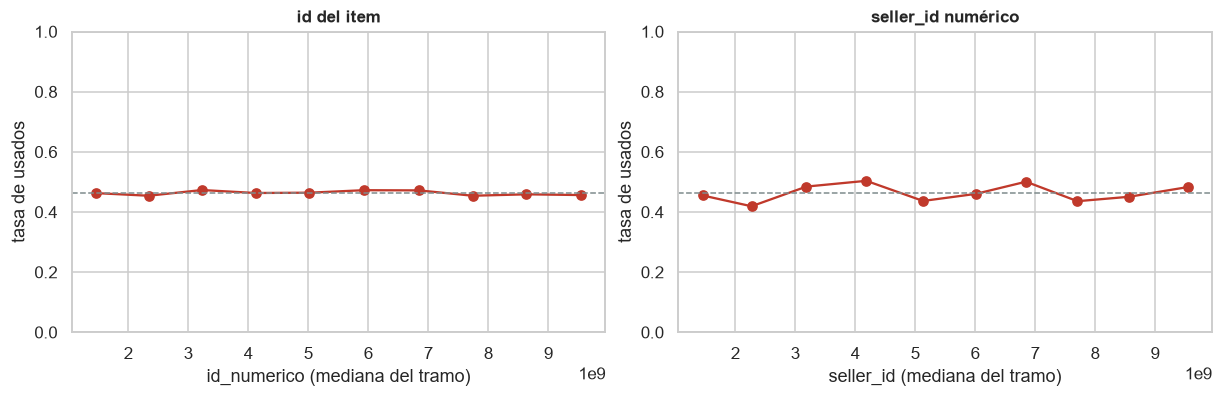

,valor
correlación del id con la fecha de creación,0.0008
parent_item_id que apunta a un item del dataset,0.0014%


In [6]:
id_numerico = train["id"].str[3:].astype(np.int64)
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
tasa_por_tramos(train.assign(id_numerico=id_numerico), "id_numerico", ejes[0], titulo="id del item")
tasa_por_tramos(train, "seller_id", ejes[1], titulo="seller_id numérico")
plt.show()

cifras({
    "correlación del id con la fecha de creación": f"{np.corrcoef(id_numerico, train['date_created'].astype('int64'))[0, 1]:.4f}",
    "parent_item_id que apunta a un item del dataset": f"{train['parent_item_id'].isin(pd.concat([train['id'], test['id']])).mean():.4%}",
})

Los ids están anonimizados. Van uniformes de 1e9 a 1e10, no se relacionan con la fecha de creación (la correlación es casi cero) y la tasa de usados es plana en todos los deciles. Lo mismo pasa con `seller_id` y con `parent_item_id`, que además casi nunca apunta a un item del dataset.

Su valor numérico no sirve, pero `seller_id` como **clave de agrupación** es de lo más valioso del dataset, como se ve en la sección de vendedores.

## 4. Train contra test

Un LightGBM intenta distinguir las filas de train de las de test. Si no puede, las dos vienen de la misma distribución y una validación cruzada sobre train es representativa del leaderboard (D01).

In [7]:
en_train, en_test = pruebas.puntajes_adversarios(train, test)
cifras({
    "AUC para distinguir train de test": f"{roc_auc_score(np.r_[np.zeros(len(train)), np.ones(len(test))], np.r_[en_train, en_test]):.3f}",
    "items de test con vendedor que está en train": f"{test['seller_id'].isin(train['seller_id']).mean():.1%}",
    "items de test con categoría que está en train": f"{test['category_id'].isin(train['category_id']).mean():.1%}",
})

,valor
AUC para distinguir train de test,0.497
items de test con vendedor que está en train,71.6%
items de test con categoría que está en train,94.7%


El AUC da 0,497, prácticamente 0,5, así que el modelo no distingue train de test.

Además, el 71,6% de los items de test tienen un vendedor que aparece en train y el 94,7% una categoría que aparece en train. Eso permite usar la tasa de usados por vendedor y por categoría, siempre calculada con folds para no filtrar el target.

## 5. Variables categóricas

Tasa de usados por nivel de cada variable, en rojo los que están por encima de la tasa global. Debajo, la diferencia entre la tasa máxima y la mínima de sus niveles con al menos 30 items.

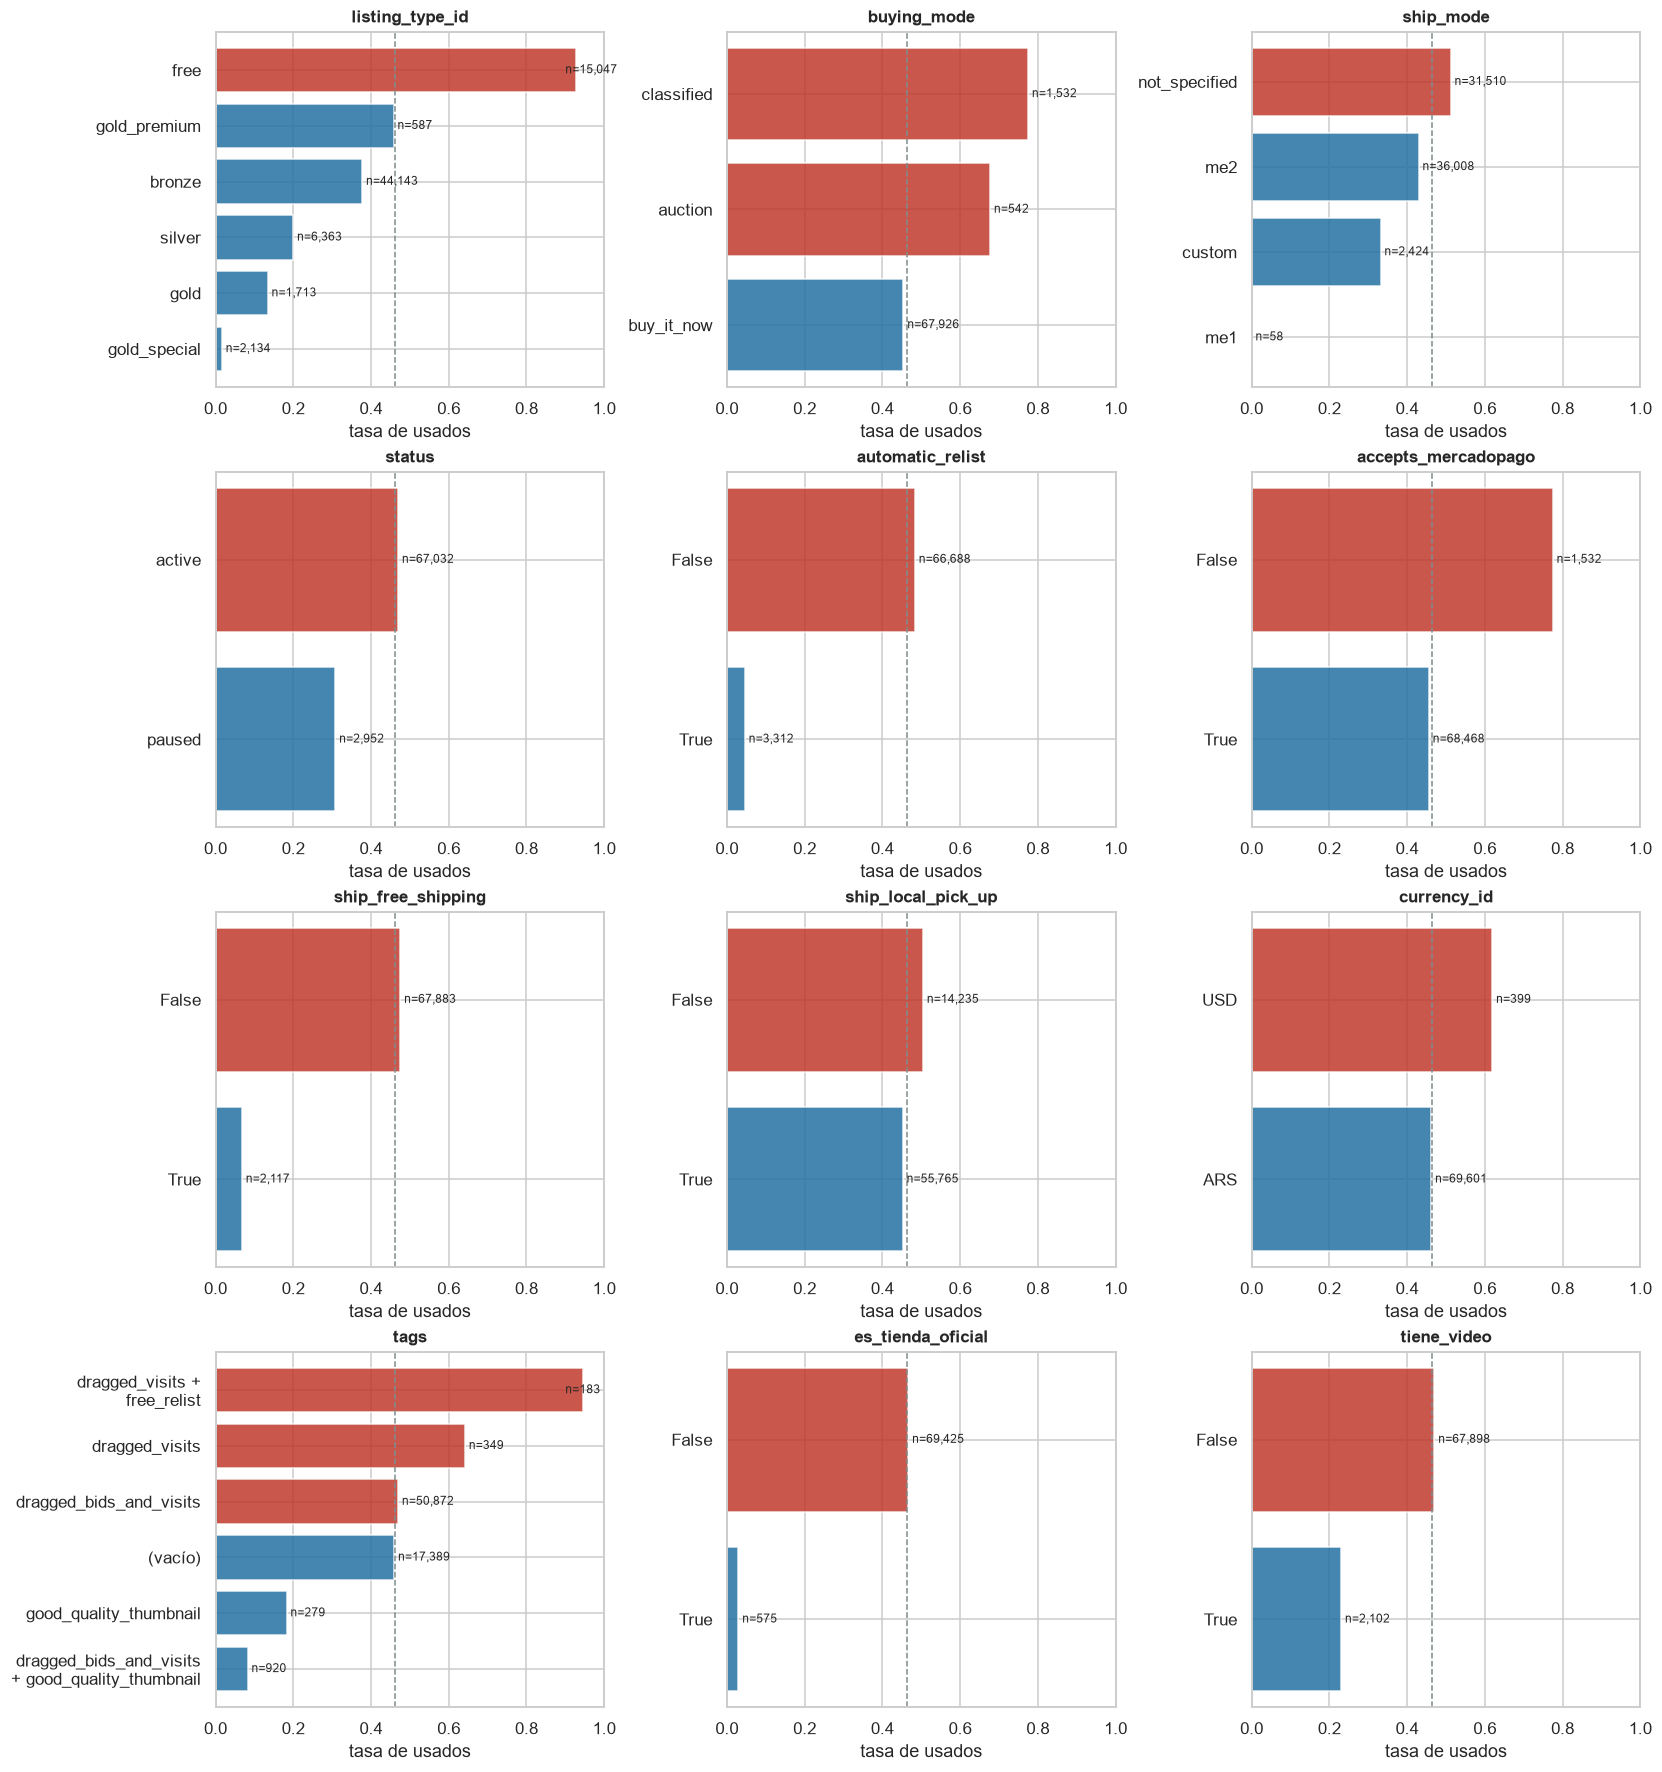

,rango de tasas
listing_type_id,0.911
tags,0.863
ship_mode,0.512
automatic_relist,0.438
es_tienda_oficial,0.437
ship_free_shipping,0.407
buying_mode,0.321
accepts_mercadopago,0.319
tiene_video,0.240
status,0.162


In [8]:
CATEGORICAS = [
    "listing_type_id", "buying_mode", "ship_mode", "status", "automatic_relist",
    "accepts_mercadopago", "ship_free_shipping", "ship_local_pick_up", "currency_id",
    "tags", "es_tienda_oficial", "tiene_video",
]
fig, ejes = plt.subplots(4, 3, figsize=(15, 16))
for columna, ax in zip(CATEGORICAS, ejes.flat):
    tasa_por_categoria(train, columna, ax)
plt.show()


def rango_de_tasas(columna, min_n=30):
    por_nivel = train.groupby(columna, dropna=False, observed=True)["y"].agg(["mean", "size"])
    por_nivel = por_nivel[por_nivel["size"] >= min_n]
    return por_nivel["mean"].max() - por_nivel["mean"].min()


pd.Series({c: rango_de_tasas(c) for c in CATEGORICAS}, name="rango de tasas").sort_values(ascending=False).round(3).to_frame()

- `listing_type_id` es la categórica más fuerte. Las publicaciones `free` son 92,7% usadas, porque publicar gratis es típico del particular que vende algo propio, mientras que `gold_special` (la más cara) es casi exclusivamente de nuevos.
- Con `automatic_relist` en True hay solo 4,6% de usados. Esa variable, el envío gratis, la tienda oficial y el video son marcas de vendedor profesional y empujan hacia "nuevo".
- En `buying_mode`, `classified` y `auction` son mayormente usados (clasificados de autos e inmuebles, subastas de objetos de colección).

### Medios de pago por fuera de MercadoPago

In [9]:
pd.DataFrame({
    f"{codigo} ({descripcion})": {"n": train[f"pay_{codigo}"].sum(), "tasa_usados": tasa(train[f"pay_{codigo}"])}
    for codigo, descripcion in datos.MEDIOS_DE_PAGO.items()
}).T.sort_values("tasa_usados").round(3)

,n,tasa_usados
MLAMP (MercadoPago),495.0,0.000
MLAOT (Tarjeta de crédito),17229.0,0.292
MLATB (Transferencia bancaria),35995.0,0.389
MLAMO (Efectivo),46910.0,0.445
MLAVS (Visa),492.0,0.500
MLAMC (MasterCard),450.0,0.511
MLAVE (Visa Electron),450.0,0.516
MLACD (Contra reembolso),439.0,0.519
MLAAM (American Express),422.0,0.521
MLAMS (Mastercard Maestro),443.0,0.526


Aceptar tarjeta de crédito (`MLAOT`) o transferencia (`MLATB`) indica un vendedor más formal, con más nuevos. Giro postal (`MLAWT`) y cheque certificado (`MLABC`) son medios viejos y se asocian a usados, igual que "acordar con el comprador" (`MLAWC`).

## 6. Stock y ventas

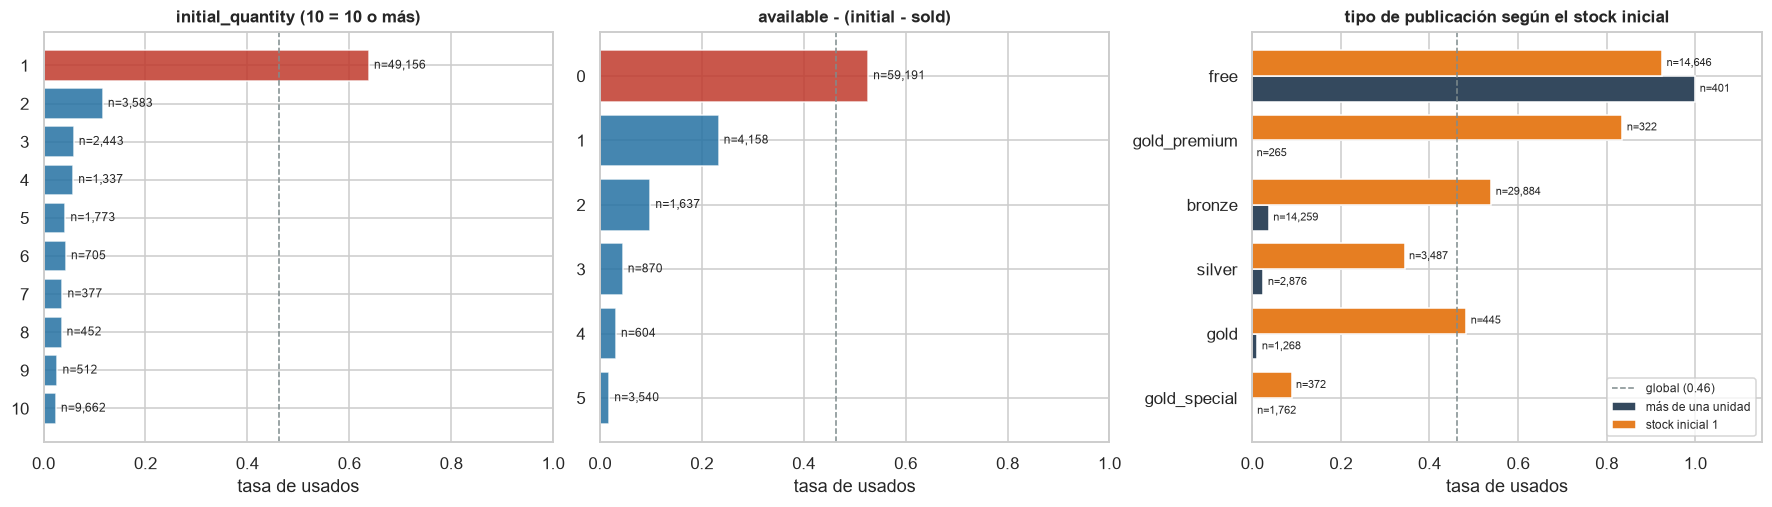

,valor
usados con stock inicial 1,63.9%
usados con más de una unidad,4.9%
items donde se repuso stock,"10,809"
usados entre los que repusieron stock,11.6%


In [10]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
recortado = train.assign(
    initial_quantity_c=train["initial_quantity"].clip(upper=10),
    stock_desbalance_c=train["stock_desbalance"].clip(-5, 5),
)
tasa_por_categoria(recortado, "initial_quantity_c", ejes[0], top=10, titulo="initial_quantity (10 = 10 o más)", por_tasa=False)
tasa_por_categoria(recortado, "stock_desbalance_c", ejes[1], top=11, titulo="available - (initial - sold)", por_tasa=False)
tasa_por_cruce(train, "listing_type_id", "iq_es_1", ejes[2], {False: "más de una unidad", True: "stock inicial 1"},
               titulo="tipo de publicación según el stock inicial")
plt.show()

repuso = train["stock_desbalance"] > 0
cifras({
    "usados con stock inicial 1": f"{tasa(train['iq_es_1']):.1%}",
    "usados con más de una unidad": f"{tasa(~train['iq_es_1']):.1%}",
    "items donde se repuso stock": f"{repuso.sum():,}",
    "usados entre los que repusieron stock": f"{tasa(repuso):.1%}",
})

- Con `initial_quantity` igual a 1 la tasa de usados es 63,9%, y con más de una unidad cae a 4,9%. Un usado es casi siempre una unidad única.
- **Relación oculta, stock repuesto.** En teoría `available = initial - sold`. En 10.809 items `available` es mayor a lo esperado, porque el vendedor repuso stock, y en esos casos la tasa de usados es 11,6%. Es una huella de comercio.
- La interacción con el tipo de publicación es fuerte, como muestra el gráfico de la derecha. Un `bronze` con stock 1 es ~54% usado, pero con más stock baja a ~4%. Un `free` es usado casi siempre, incluso con varias unidades. Los árboles capturan este cruce solos.
- **Relación oculta, `gold_premium`.** Sola parece neutra (~46% usados), pero esconde dos poblaciones opuestas. Con más de una unidad es 0% usado y con stock 1 es ~84% usado (bienes caros de unidad única, como autos o inmuebles, publicados con la mejor exposición).
- Haber vendido algo también empuja a "nuevo", como muestra la tabla de abajo.

In [11]:
train.groupby(["iq_es_1", "vendio_algo"])["y"].agg(["mean", "size"]).round(3)

mean   size
iq_es_1 vendio_algo              
False   False        0.060  13350
        True         0.030   7494
True    False        0.677  44748
        True         0.246   4408

## 7. Precio

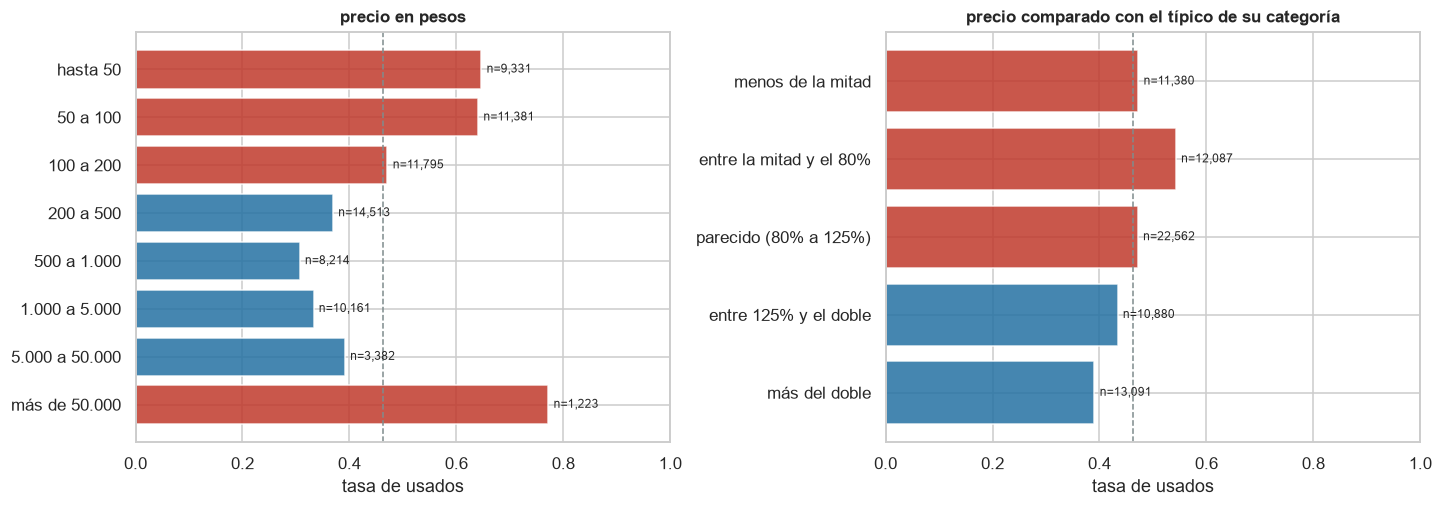

In [12]:
tramo_de_precio = pd.cut(train["price"], [0, 50, 100, 200, 500, 1000, 5000, 50000, np.inf],
                         labels=["hasta 50", "50 a 100", "100 a 200", "200 a 500", "500 a 1.000",
                                 "1.000 a 5.000", "5.000 a 50.000", "más de 50.000"])
# Cuántas veces el precio típico (la mediana) de su categoría
relativo = np.exp(train["log_price_rel_categoria"])
frente_a_su_categoria = pd.cut(relativo, [0, 0.5, 0.8, 1.25, 2, np.inf],
                               labels=["menos de la mitad", "entre la mitad y el 80%", "parecido (80% a 125%)",
                                       "entre 125% y el doble", "más del doble"])
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
tasa_por_categoria(train.assign(precio=tramo_de_precio), "precio", ejes[0], por_tasa=False,
                   titulo="precio en pesos")
tasa_por_categoria(train.assign(relativo=frente_a_su_categoria), "relativo", ejes[1], por_tasa=False,
                   titulo="precio comparado con el típico de su categoría")
plt.show()

El gráfico de la izquierda agrupa los items por su precio en pesos. La relación entre precio y condición no es monótona. Hasta 100 pesos, casi dos de cada tres items son usados (libros, revistas, discos). Entre 200 y 50.000 pesos predominan los nuevos, y por encima de 50.000 los usados vuelven a ser mayoría (autos e inmuebles clasificados).

El de la derecha compara cada precio con el precio típico de su categoría, que es la mediana de lo que cuestan los items de esa categoría. La idea es que 500 pesos es caro para un libro y barato para un celular. La diferencia que aparece es chica. Los items algo más baratos que lo típico tienen un poco más de usados (54%) y los que cuestan más del doble, un poco menos (39%). Los mucho más baratos quedan en el promedio.

### Psicología de precios

In [13]:
tabla_de_banderas(["price_con_decimales", "price_termina_en_9", "price_multiplo_100"]).round(3)

,n,usados_si_true,usados_si_false
price_con_decimales,9613.0,0.188,0.507
price_termina_en_9,10134.0,0.233,0.502
price_multiplo_100,15460.0,0.652,0.410


**Relación oculta.** El *formato* del precio delata al tipo de vendedor. Los comercios usan precios con centavos o terminados en 9 (199.99, 349) y son mayormente nuevos. Los particulares redondean a múltiplos de 100 y son mayormente usados.

## 8. Variables temporales

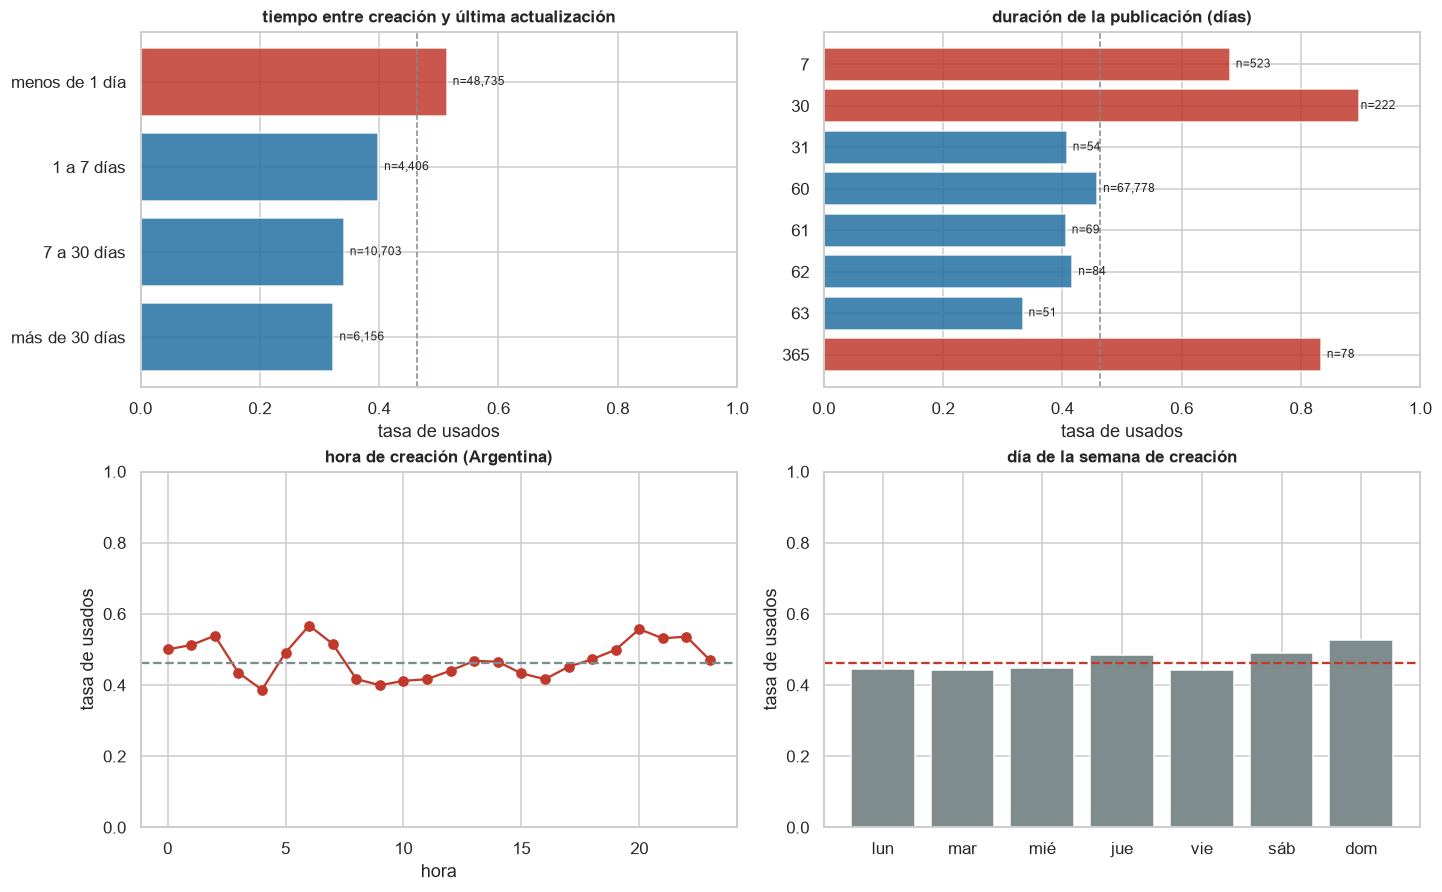

,fecha de creación
min,2013-05-21
max,2015-10-15


In [14]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
actualizacion = pd.cut(train["dias_hasta_update"], [-1, 1, 7, 30, np.inf],
                       labels=["menos de 1 día", "1 a 7 días", "7 a 30 días", "más de 30 días"])
tasa_por_categoria(train.assign(actualizacion=actualizacion), "actualizacion", ejes[0, 0], por_tasa=False,
                   titulo="tiempo entre creación y última actualización")
tasa_por_categoria(train.assign(duracion=train["duracion_dias"].clip(upper=400)), "duracion", ejes[0, 1],
                   top=8, titulo="duración de la publicación (días)", por_tasa=False)
por_hora = train.groupby("hora_creacion")["y"].mean()
ejes[1, 0].plot(por_hora.index, por_hora.values, marker="o", color=COLOR_USADO)
ejes[1, 0].axhline(tasa_global, color=COLOR_NEUTRO, ls="--")
ejes[1, 0].set(title="hora de creación (Argentina)", xlabel="hora", ylabel="tasa de usados", ylim=(0, 1))
por_dia = train.groupby("dia_semana")["y"].mean()
ejes[1, 1].bar(["lun", "mar", "mié", "jue", "vie", "sáb", "dom"], por_dia.values, color=COLOR_NEUTRO)
ejes[1, 1].axhline(tasa_global, color=COLOR_USADO, ls="--")
ejes[1, 1].set(title="día de la semana de creación", ylabel="tasa de usados", ylim=(0, 1))
plt.show()

train["date_created"].agg(["min", "max"]).dt.date.to_frame("fecha de creación")

- Los items se crearon entre mayo de 2013 y octubre de 2015, casi todos entre agosto y octubre de 2015. La fecha en sí no tiene tendencia.
- Los items que se actualizaron días después de creados son más nuevos, porque el comerciante edita precio y stock y el particular publica y se olvida.
- La duración estándar es 60 días. Las de 7, 30 y 365 días son mayormente usados, por ser los formatos de clasificados y de publicaciones gratuitas.
- Hay un patrón horario suave, en hora argentina. De noche, entre las 19 y las 2, y los fines de semana publican más particulares (más usados). Entre las 8 y las 18 de lunes a viernes predominan los comercios.

## 9. Texto del título y la garantía

Las palabras de cada campo más asociadas a cada clase, entre las que aparecen en suficientes items.

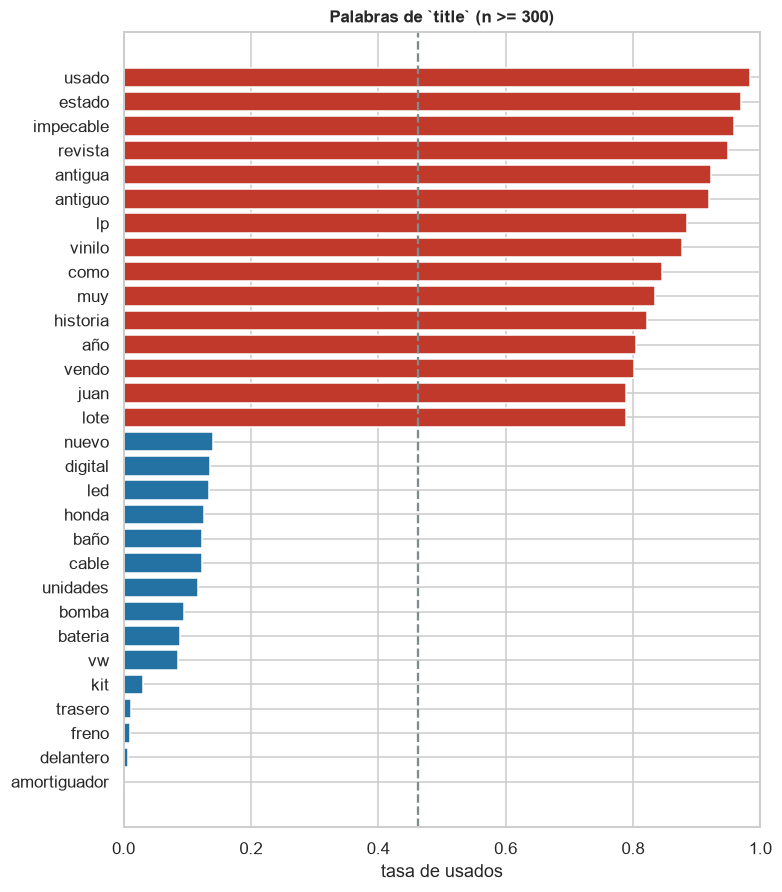

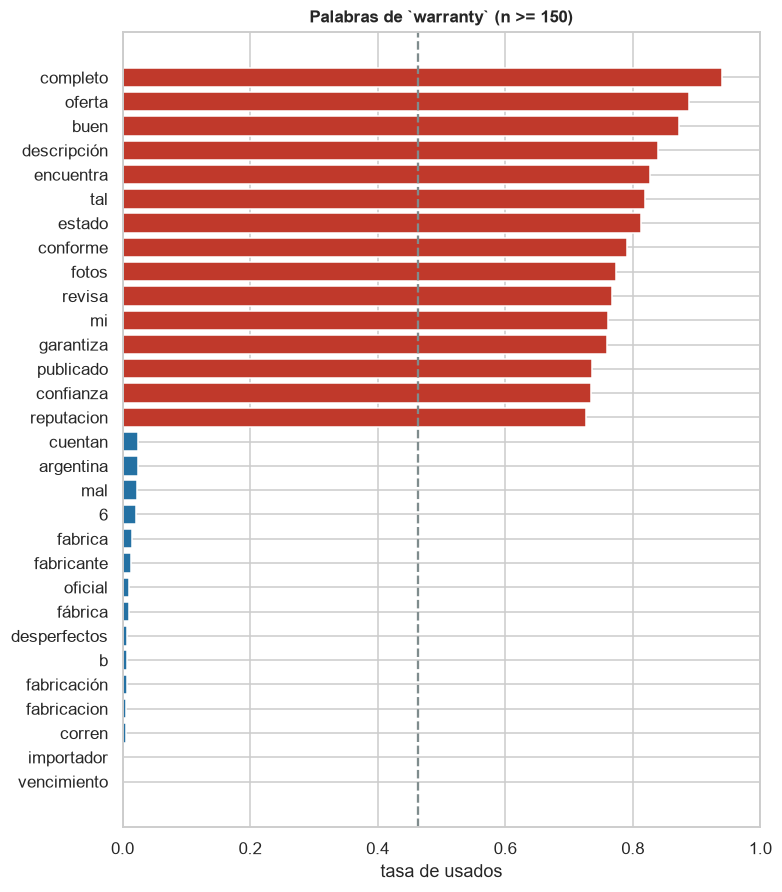

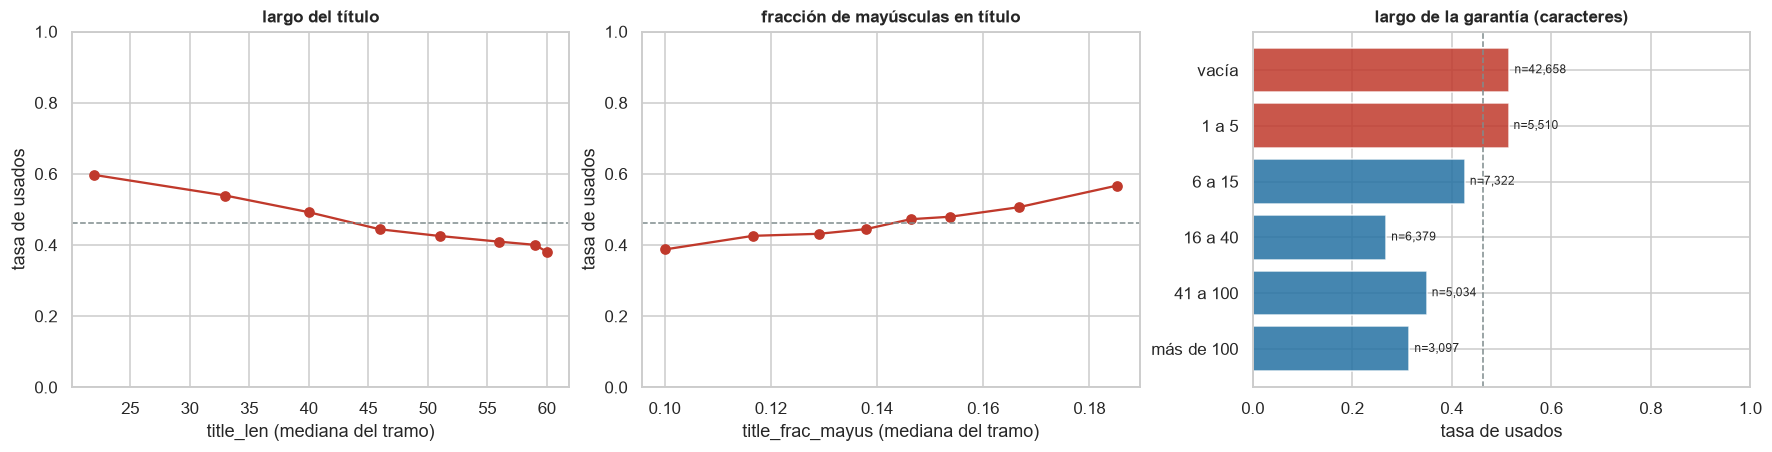

In [15]:
def tasa_por_palabra(serie, minimo):
    palabras = serie.fillna("").map(lambda t: set(re.findall(r"[a-záéíóúñü0-9]+", t.lower())))
    total = Counter(p for ps in palabras for p in ps)
    usados = Counter(p for ps, usado in zip(palabras, train["y"]) if usado for p in ps)
    tabla = pd.DataFrame({"n": total, "tasa_usados": usados}).fillna(0)
    tabla = tabla[tabla["n"] >= minimo]
    tabla["tasa_usados"] = tabla["tasa_usados"] / tabla["n"]
    return tabla


for columna, minimo in [("title", 300), ("warranty", 150)]:
    palabras = tasa_por_palabra(train[columna], minimo)
    extremos = pd.concat([palabras.nlargest(15, "tasa_usados"), palabras.nsmallest(15, "tasa_usados")])
    extremos = extremos.sort_values("tasa_usados")
    fig, ax = plt.subplots(figsize=(7, 8))
    colores = [COLOR_USADO if t > tasa_global else COLOR_NUEVO for t in extremos["tasa_usados"]]
    ax.barh(extremos.index, extremos["tasa_usados"], color=colores)
    ax.axvline(tasa_global, color=COLOR_NEUTRO, ls="--")
    ax.set(xlim=(0, 1), xlabel="tasa de usados", title=f"Palabras de `{columna}` (n >= {minimo})")
    plt.show()

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
tasa_por_tramos(train, "title_len", ejes[0], tramos=8, titulo="largo del título")
tasa_por_tramos(train, "title_frac_mayus", ejes[1], tramos=8, titulo="fracción de mayúsculas en título")
largo = pd.cut(train["warranty_len"], [-1, 0, 5, 15, 40, 100, 1e5],
               labels=["vacía", "1 a 5", "6 a 15", "16 a 40", "41 a 100", "más de 100"])
tasa_por_categoria(train.assign(largo=largo), "largo", ejes[2], titulo="largo de la garantía (caracteres)", por_tasa=False)
plt.show()

El texto es muy informativo y complementa a las variables estructuradas.

- **Título.** Aparecen palabras explícitas ("usado", "impecable", "excelente estado"), pero sobre todo el *tipo de producto*. Revistas, vinilos, LPs, libros y cosas "antiguas" son usados; repuestos de auto (amortiguador, freno, kit), electrónica (led, usb, cargador) y textiles son nuevos. Artículos como "el", "la", "los" aparecen como usados porque son típicos de títulos de libros y discos.
- **Garantía.** Los nuevos hablan de "fabricación", "fábrica", "oficial", "importador", "meses". Los usados escriben frases sobre "estado", "fotos", "reputación", "conforme", porque el vendedor responde por su palabra y no por un fabricante. Una garantía corta o vacía no discrimina, pero una de 15 a 40 caracteres ("6 meses de garantía") es fuertemente nueva.
- Los títulos cortos y con muchas mayúsculas son más de particulares.

El modelo aprovecha esto con palabras clave en título y garantía y con perfiles por palabra, sin ningún modelo de texto.

## 10. Señales semánticas en palabras clave y ficha técnica

Cada bandera es verdadera si el título (`t_`), la garantía (`w_`) o la ficha técnica (`attr_`) cumple un patrón. Los patrones están en `datos.py`.

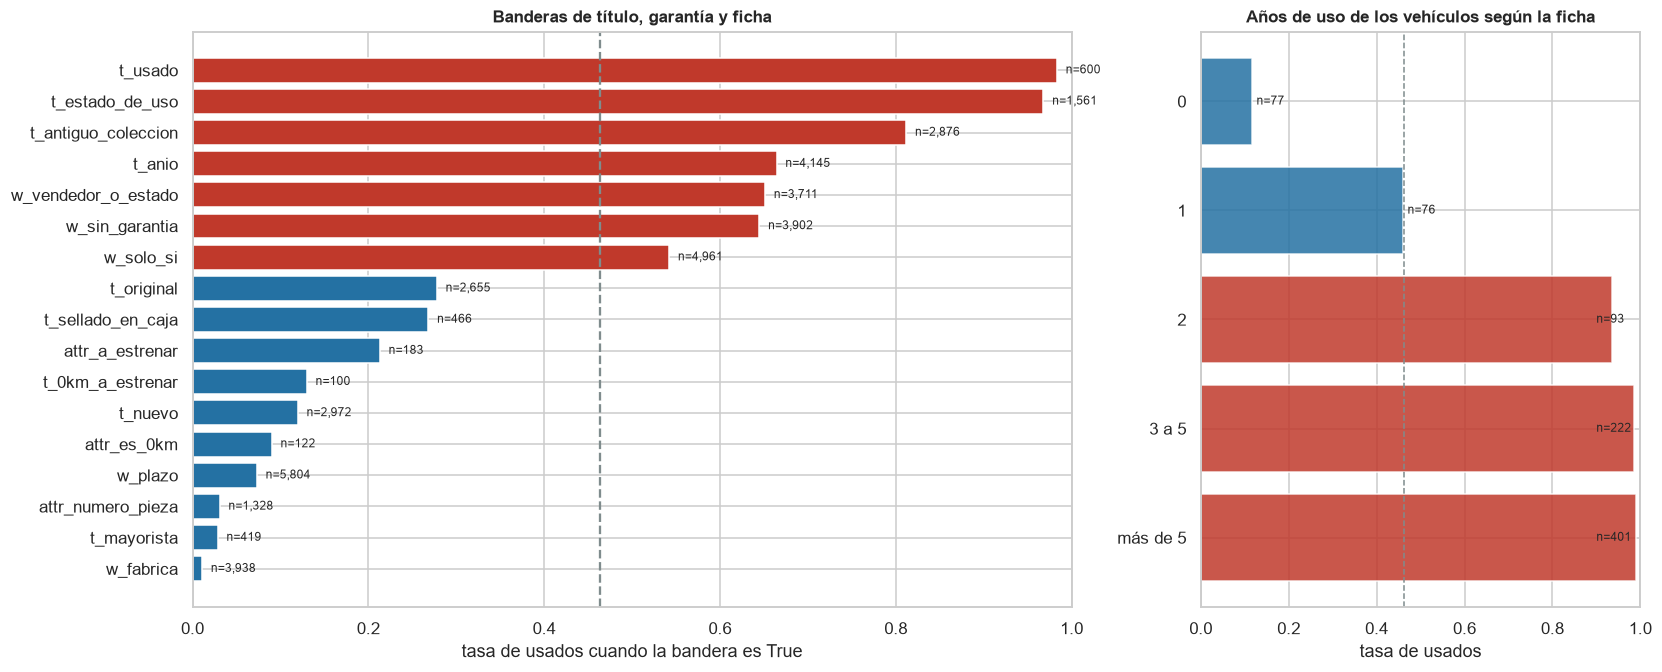

,n,usados_si_true,usados_si_false
w_fabrica,3938.0,0.011,0.490
t_mayorista,419.0,0.029,0.466
attr_numero_pieza,1328.0,0.031,0.471
w_plazo,5804.0,0.073,0.498
attr_es_0km,122.0,0.090,0.464
t_nuevo,2972.0,0.120,0.478
t_0km_a_estrenar,100.0,0.130,0.464
attr_a_estrenar,183.0,0.213,0.464
t_sellado_en_caja,466.0,0.268,0.464
t_original,2655.0,0.278,0.470


In [16]:
banderas = tabla_de_banderas([*datos.PATRONES_TITULO, *datos.PATRONES_GARANTIA,
                              "attr_es_0km", "attr_a_estrenar", "attr_numero_pieza"]).sort_values("usados_si_true")
fig, ejes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2, 1]})
colores = [COLOR_USADO if t > tasa_global else COLOR_NUEVO for t in banderas["usados_si_true"]]
ejes[0].barh(banderas.index, banderas["usados_si_true"], color=colores)
for i, (t, n) in enumerate(zip(banderas["usados_si_true"], banderas["n"])):
    ejes[0].text(t + 0.01, i, f"n={int(n):,}", va="center", fontsize=8)
ejes[0].axvline(tasa_global, color=COLOR_NEUTRO, ls="--")
ejes[0].set(xlim=(0, 1), xlabel="tasa de usados cuando la bandera es True", title="Banderas de título, garantía y ficha")
vehiculos = train[train["attr_anios_de_uso"].notna()]
vehiculos = vehiculos.assign(anios_de_uso=pd.cut(vehiculos["attr_anios_de_uso"], [-2, 0, 1, 2, 5, 100],
                                                 labels=["0", "1", "2", "3 a 5", "más de 5"]))
tasa_por_categoria(vehiculos, "anios_de_uso", ejes[1], min_n=10, titulo="Años de uso de los vehículos según la ficha",
                   por_tasa=False)
plt.show()
banderas.round(3)

Banderas simples sobre el texto y la ficha técnica capturan buena parte de lo que "dice" la publicación. Algunas son casi deterministas, aunque cubren pocos items.

- **Título.** "Usado" y las descripciones de estado ("como nuevo", "impecable", "poco uso") son ~97% usados. Hay que separar "como nuevo" de "nuevo", porque el primero describe algo usado y el segundo baja la tasa a ~12%. La venta mayorista ("x 10 unidades", "por mayor") es casi siempre de nuevos. "Antiguo", "colección" o un año en el título apuntan a objetos usados (discos, revistas, antigüedades).
- **Garantía.** Lo que importa es *quién* garantiza. Si la garantía es de fábrica, oficial o del importador, el item es nuevo (~1% usados). Si tiene un plazo concreto, también (~7%). Si el vendedor habla de su reputación o de que el producto funciona, es usado (~65%). Un "Sí" a secas no informa nada.
- **Ficha técnica.** En vehículos, los del año son mayormente nuevos (~12% usados), con un año de uso quedan en la mitad y desde 2 años de uso son ~99% usados. En inmuebles, "A estrenar" baja la tasa al ~21%. El número de pieza identifica repuestos nuevos (~3%).

Como cada bandera cubre pocos items, su aporte al accuracy global es menor que el de las variables de stock o vendedor, pero resuelven casos donde esas variables dudan, por ejemplo un particular que vende algo nuevo en caja.

## 11. Formato de las fotos

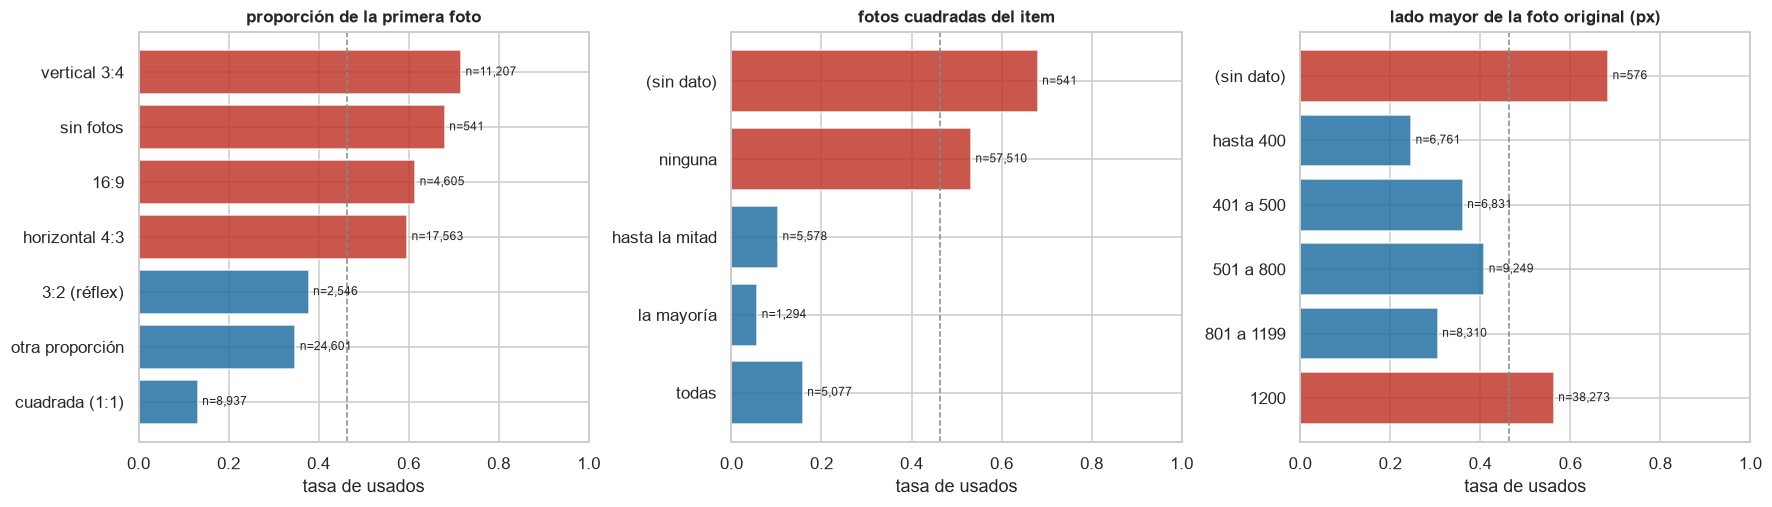

In [17]:
aspecto = train["pic0_aspecto"].round(2)
formato = pd.Series("otra proporción", index=train.index)
formato[aspecto == 1] = "cuadrada (1:1)"
formato[aspecto.isin([1.33, 1.34])] = "horizontal 4:3"
formato[aspecto.isin([0.75, 0.74])] = "vertical 3:4"
formato[aspecto.isin([1.78, 1.79, 0.56])] = "16:9"
formato[aspecto.isin([1.5, 0.67])] = "3:2 (réflex)"
formato[train["pic0_aspecto"].isna()] = "sin fotos"

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
tasa_por_categoria(train.assign(formato=formato), "formato", ejes[0], titulo="proporción de la primera foto")
tasa_por_categoria(
    train.assign(cuadradas=pd.cut(train["pic_frac_cuadradas"], [-0.01, 0, 0.5, 0.99, 1],
                                  labels=["ninguna", "hasta la mitad", "la mayoría", "todas"])),
    "cuadradas", ejes[1], titulo="fotos cuadradas del item", por_tasa=False)
tasa_por_categoria(
    train.assign(lado=pd.cut(train["pic_lado_max"], [0, 400, 500, 800, 1199, 1200],
                             labels=["hasta 400", "401 a 500", "501 a 800", "801 a 1199", "1200"])),
    "lado", ejes[2], titulo="lado mayor de la foto original (px)", por_tasa=False)
plt.show()

**Relación oculta.** La proporción de la foto delata cómo se sacó. Una foto cuadrada es de catálogo o de estudio, y solo el 13,1% de esos items es usado. Una foto vertical 3:4 es de celular (71,6% usados) y una horizontal 4:3 es de cámara compacta (59,7%). La proporción 3:2, propia de cámaras réflex, vuelve a ser más de comercio (37,8%).

La resolución va en el mismo sentido. Las fotos que llegan al tope de 1200 px son fotos caseras subidas sin procesar, mientras que las de comercios suelen venir recortadas y achicadas. Ninguna de estas variables mira el contenido de la imagen, solo sus dimensiones.

## 12. Vendedores, la relación oculta más fuerte

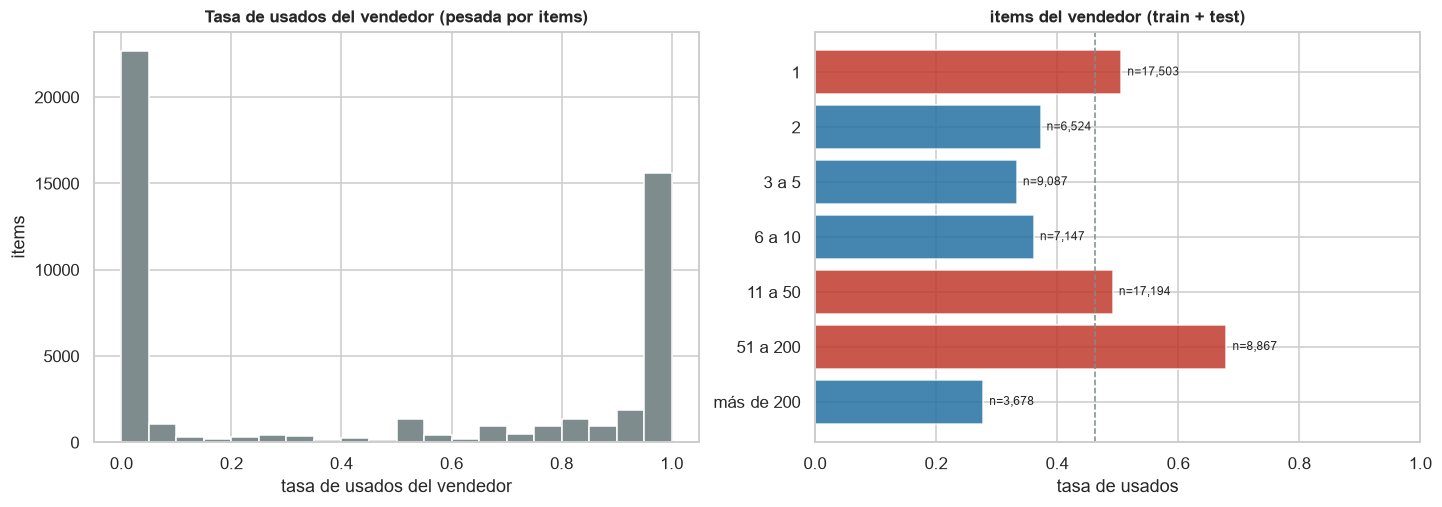

,valor
vendedores en train,"27,949"
items en vendedores puros (entre los de más de un item),69.6%
accuracy prediciendo con los otros items del vendedor,0.923
items de train con vendedor repetido,71.5%


In [18]:
def pureza(clave, min_items=2):
    """Fracción de los items que está en grupos donde todos son nuevos o todos usados."""
    por_grupo = train.groupby(clave)["y"].agg(["mean", "size"])
    por_grupo = por_grupo[por_grupo["size"] >= min_items]
    puros = por_grupo[(por_grupo["mean"] == 0) | (por_grupo["mean"] == 1)]["size"].sum()
    return puros / por_grupo["size"].sum(), por_grupo


def acierto_con_los_otros(clave):
    """Accuracy de predecir la clase mayoritaria de los *otros* items del grupo, y a cuántos items se aplica."""
    grupo = train.groupby(clave)["y"]
    otros = grupo.transform("size") - 1
    tasa_de_los_otros = (grupo.transform("sum") - train["y"]) / otros.replace(0, np.nan)
    evaluables = otros > 0
    prediccion = (tasa_de_los_otros[evaluables] > 0.5).astype(int)
    return (prediccion == train.loc[evaluables, "y"]).mean(), evaluables.mean()


fraccion_pura, por_vendedor = pureza("seller_id")
acierto, cobertura = acierto_con_los_otros("seller_id")
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].hist(por_vendedor["mean"], bins=20, weights=por_vendedor["size"], color=COLOR_NEUTRO)
ejes[0].set(title="Tasa de usados del vendedor (pesada por items)", xlabel="tasa de usados del vendedor", ylabel="items")
tasa_por_categoria(train.assign(seller_n=pd.cut(train["seller_n_items"], [0, 1, 2, 5, 10, 50, 200, 1e5],
                                                      labels=["1", "2", "3 a 5", "6 a 10", "11 a 50", "51 a 200", "más de 200"])),
                   "seller_n", ejes[1], titulo="items del vendedor (train + test)", por_tasa=False)
plt.show()

cifras({
    "vendedores en train": f"{train['seller_id'].nunique():,}",
    "items en vendedores puros (entre los de más de un item)": f"{fraccion_pura:.1%}",
    "accuracy prediciendo con los otros items del vendedor": f"{acierto:.3f}",
    "items de train con vendedor repetido": f"{cobertura:.1%}",
})

Hay 27.949 vendedores en train. Entre los items de vendedores con más de un item, el 69,6% pertenece a vendedores **puros** (todo nuevo o todo usado), y la distribución es una U casi perfecta. Un vendedor es un comercio o un particular, rara vez ambas cosas.

Si para cada item se predice la clase mayoritaria de los *otros* items del mismo vendedor, el accuracy es **0,923** sobre el 71,5% de train que tiene vendedor repetido. Por eso la tasa de usados del vendedor, calculada con folds, es una de las variables más fuertes del modelo.

El tamaño del vendedor no es monótono. Los de 2 a 10 items son mayormente nuevos, los de 50 a 200 vuelven a ser usados (revendedores de libros, discos, coleccionables) y los más grandes son comercios.

### Perfil del vendedor, sin usar el target

Agregando por vendedor las variables del item (sobre train + test, sin mirar el target) se obtiene un perfil que también existe para los vendedores que solo están en test. Los gráficos usan solo vendedores con 3 o más items.

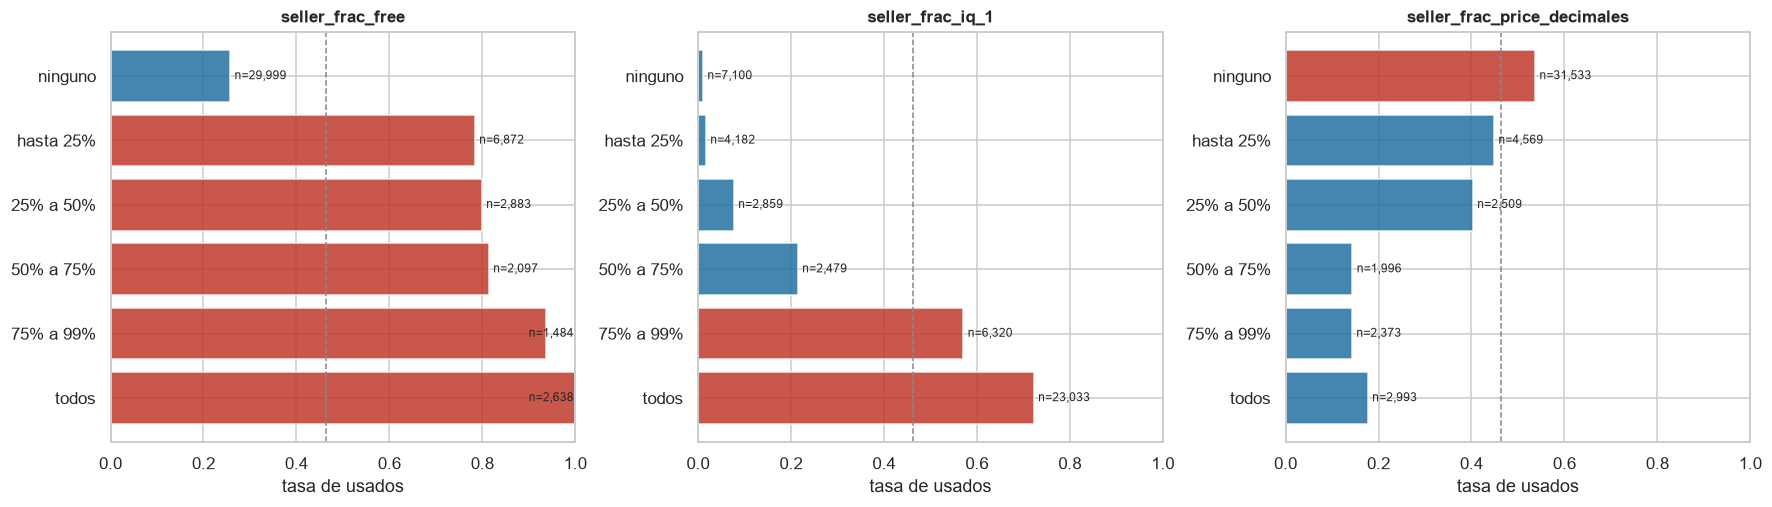

,valor
usados entre los no free de vendedores que alguna vez publicaron gratis,70.1%
usados entre los no free de vendedores que nunca publicaron gratis,26.3%


In [19]:
con_varios = train["seller_n_items"] >= 3
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for columna, ax in zip(["seller_frac_free", "seller_frac_iq_1", "seller_frac_price_decimales"], ejes):
    cortes = pd.cut(train.loc[con_varios, columna], [-0.01, 0, 0.25, 0.5, 0.75, 0.99, 1],
                    labels=["ninguno", "hasta 25%", "25% a 50%", "50% a 75%", "75% a 99%", "todos"])
    tasa_por_categoria(train[con_varios].assign(**{columna: cortes}), columna, ax, top=6, por_tasa=False)
plt.show()

no_free = train["listing_type_id"] != "free"
cifras({
    "usados entre los no free de vendedores que alguna vez publicaron gratis": f"{tasa(no_free & (train['seller_frac_free'] > 0)):.1%}",
    "usados entre los no free de vendedores que nunca publicaron gratis": f"{tasa(no_free & (train['seller_frac_free'] == 0)):.1%}",
})

**Relación oculta.** Lo que hace un vendedor en *sus otras* publicaciones dice más que el item mismo. Si se toman solo los items que **no** son `free`, los de vendedores que alguna vez publicaron gratis son 70,1% usados, contra 26,3% de los vendedores que nunca lo hicieron. Lo mismo pasa con la fracción de items con stock 1 y la fracción de precios con centavos.

## 13. Comportamiento del vendedor en sus otras publicaciones

Solo vendedores con 3 o más items, contando train y test.

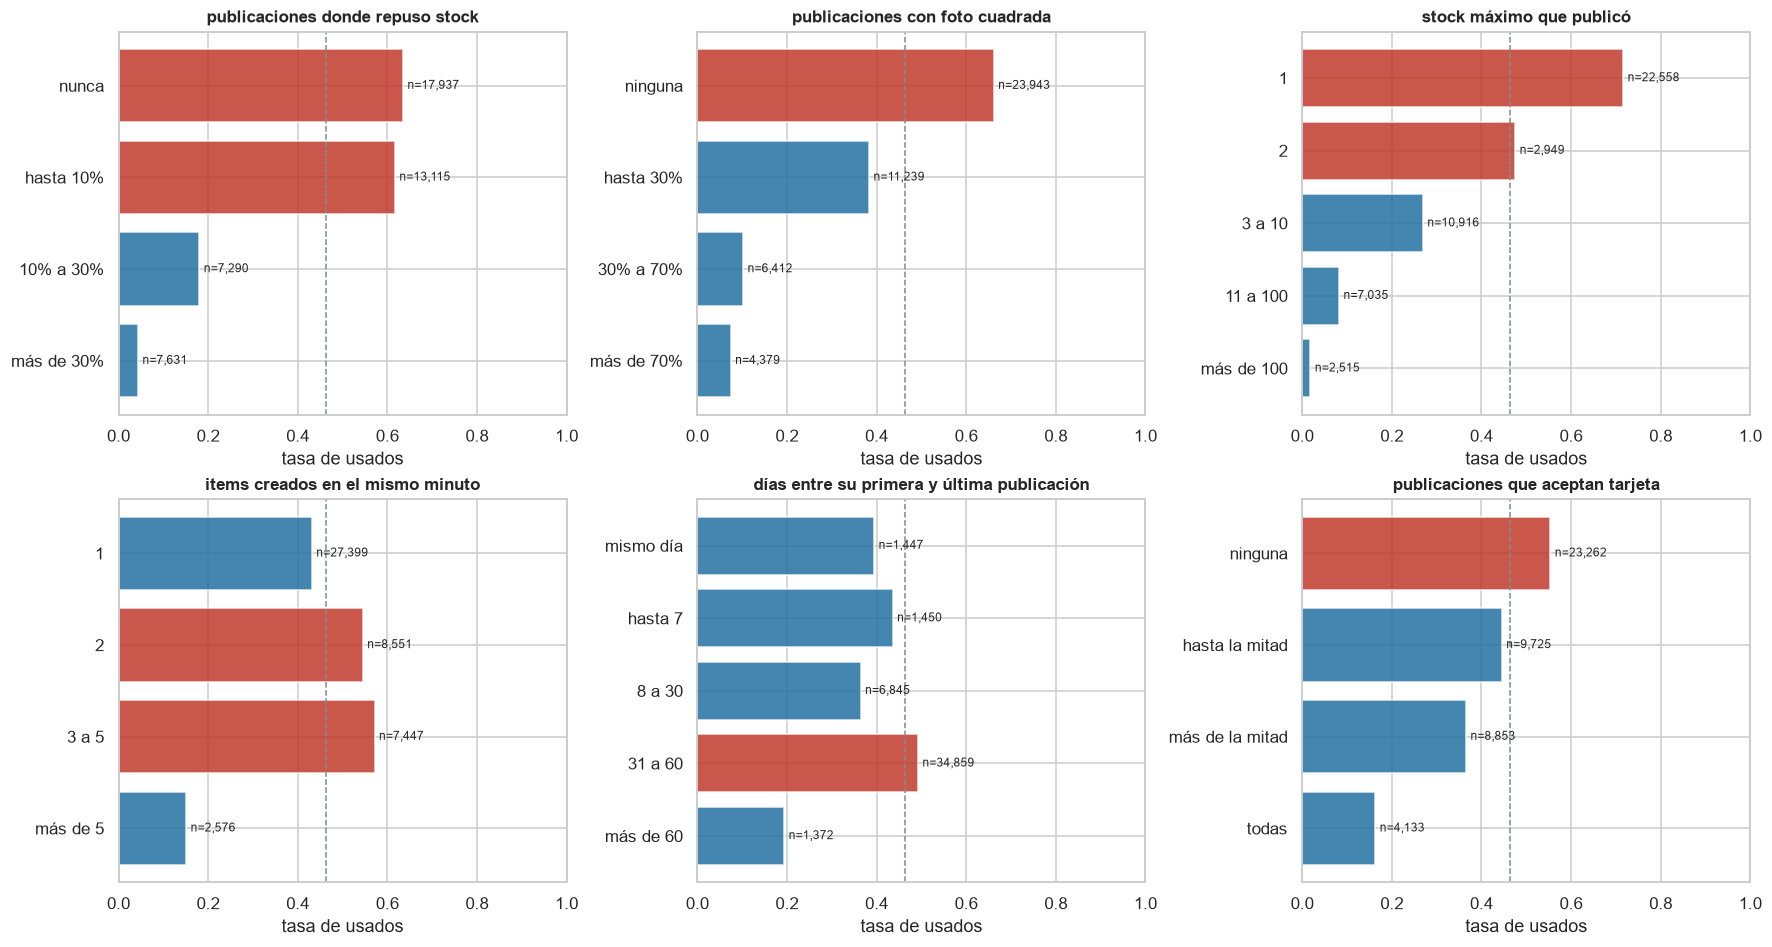

,tasa de usados
vendedor que nunca repone stock,63.5%
vendedor que repone en más del 30%,4.4%
stock máximo de 2 o menos,65.3%
stock máximo de más de 10,6.3%
más de 5 items creados en el mismo minuto,15.1%
"sin foto cuadrada, vendedor con más del 30% cuadradas",12.4%
"sin foto cuadrada, vendedor que nunca las usa",60.3%


In [20]:
# Para cada variable, los cortes de los tramos, sus nombres y el título del gráfico
paneles = {
    "seller_frac_repuso_stock": ([-0.01, 0, 0.1, 0.3, 1], ["nunca", "hasta 10%", "10% a 30%", "más de 30%"],
                                 "publicaciones donde repuso stock"),
    "seller_frac_foto_cuadrada": ([-0.01, 0, 0.3, 0.7, 1], ["ninguna", "hasta 30%", "30% a 70%", "más de 70%"],
                                  "publicaciones con foto cuadrada"),
    "seller_max_initial_quantity": ([0, 1, 2, 10, 100, 1e5], ["1", "2", "3 a 10", "11 a 100", "más de 100"],
                                    "stock máximo que publicó"),
    "seller_items_mismo_minuto": ([0, 1, 2, 5, 1e5], ["1", "2", "3 a 5", "más de 5"],
                                  "items creados en el mismo minuto"),
    "seller_span_dias": ([-1, 0, 7, 30, 60, 1e4], ["mismo día", "hasta 7", "8 a 30", "31 a 60", "más de 60"],
                         "días entre su primera y última publicación"),
    "seller_frac_pago_tarjeta": ([-0.01, 0, 0.5, 0.99, 1], ["ninguna", "hasta la mitad", "más de la mitad", "todas"],
                                 "publicaciones que aceptan tarjeta"),
}
fig, ejes = plt.subplots(2, 3, figsize=(16, 8.5))
for (columna, (cortes, nombres, titulo)), ax in zip(paneles.items(), ejes.flat):
    tramos = pd.cut(train.loc[con_varios, columna], cortes, labels=nombres)
    tasa_por_categoria(train[con_varios].assign(**{columna: tramos}), columna, ax, top=6, titulo=titulo,
                       por_tasa=False)
plt.show()

sin_cuadrada = ~train["pic_tiene_cuadrada"]
cifras({
    "vendedor que nunca repone stock": f"{tasa(con_varios & (train['seller_frac_repuso_stock'] == 0)):.1%}",
    "vendedor que repone en más del 30%": f"{tasa(con_varios & (train['seller_frac_repuso_stock'] > 0.3)):.1%}",
    "stock máximo de 2 o menos": f"{tasa(train['seller_max_initial_quantity'] <= 2):.1%}",
    "stock máximo de más de 10": f"{tasa(train['seller_max_initial_quantity'] > 10):.1%}",
    "más de 5 items creados en el mismo minuto": f"{tasa(train['seller_items_mismo_minuto'] > 5):.1%}",
    "sin foto cuadrada, vendedor con más del 30% cuadradas": f"{tasa(sin_cuadrada & (train['seller_frac_foto_cuadrada'] > 0.3)):.1%}",
    "sin foto cuadrada, vendedor que nunca las usa": f"{tasa(sin_cuadrada & (train['seller_frac_foto_cuadrada'] == 0)):.1%}",
}).rename(columns={"valor": "tasa de usados"})

- **Reposición de stock.** Si el vendedor nunca repone, el 63,5% de sus items son usados. Si repone en más del 30% de sus publicaciones, el 4,4%.
- **Stock máximo.** Un vendedor que nunca publicó más de 2 unidades de nada tiene 65,3% de usados. Si alguna vez publicó más de 10, tiene 6,3%.
- **Carga masiva.** Más de 5 publicaciones creadas en el mismo minuto indican una herramienta de carga, propia de comercios (15,1% usados).
- **Fotos del vendedor.** Quien usa fotos cuadradas en otras publicaciones es comercio aunque en este item no lo haga. Entre los items *sin* foto cuadrada, los de vendedores con más del 30% de publicaciones con fotos cuadradas son 12,4% usados, contra 60,3% de los vendedores que nunca las usan.

Estas variables explican por qué un mismo item (stock 1, `bronze`, sin garantía) puede ser nuevo o usado, según quién lo publique.

## 14. Categorías

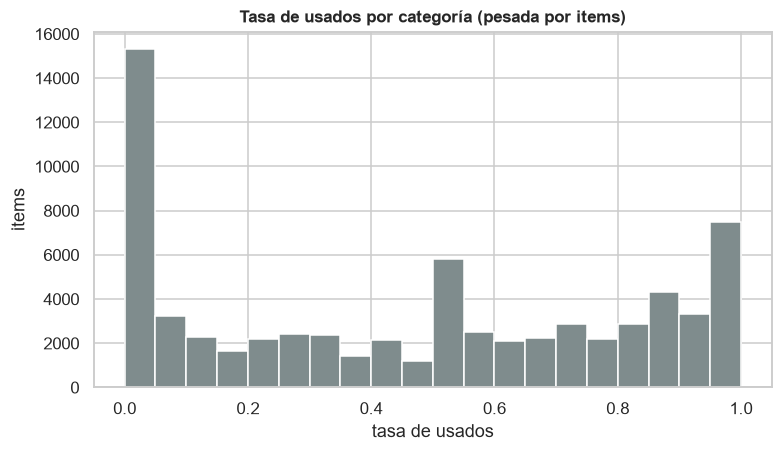

,valor
categorías en train,"9,570"
accuracy prediciendo con los otros items de la categoría,0.780
items de train con categoría repetida,94.7%
items en categorías puras (entre las de 20 o más items),9.4%


In [21]:
fraccion_pura, _ = pureza("category_id", min_items=20)
acierto, cobertura = acierto_con_los_otros("category_id")
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(train.groupby("category_id")["y"].mean(), bins=20, color=COLOR_NEUTRO,
        weights=train.groupby("category_id").size())
ax.set(title="Tasa de usados por categoría (pesada por items)", xlabel="tasa de usados", ylabel="items")
plt.show()

cifras({
    "categorías en train": f"{train['category_id'].nunique():,}",
    "accuracy prediciendo con los otros items de la categoría": f"{acierto:.3f}",
    "items de train con categoría repetida": f"{cobertura:.1%}",
    "items en categorías puras (entre las de 20 o más items)": f"{fraccion_pura:.1%}",
})

Hay 9.570 categorías, que son hojas del árbol de MercadoLibre sin nombre. Predecir la clase mayoritaria de los otros items de la misma categoría da un accuracy de **0,780** sobre el 94,7% de train evaluable. Entre las categorías con 20 o más items, solo el 9,4% de los items está en categorías puras. La categoría ayuda, pero bastante menos que el vendedor.

Abajo, las categorías más grandes.

In [22]:
train.groupby("category_id")["y"].agg(tasa_usados="mean", n="size").sort_values("n", ascending=False).head(12).round(3)

,tasa_usados,n
category_id,,
MLA1227,0.508,3180
MLA2044,0.746,1359
MLA41287,0.868,629
MLA3530,0.402,542
MLA2038,0.936,468
MLA15171,0.624,410
MLA15328,0.985,333
MLA15204,0.470,319
MLA1383,0.924,315


## 15. Perfil por palabra del título

El título dice qué producto es, y hay productos que casi siempre son usados (un vinilo, una revista) o nuevos (un repuesto, un cargador). Para capturarlo **sin usar el target** se arma un perfil por palabra, en dos pasos.

1. Para cada palabra se mira cómo se publican los *otros* items que la contienen, o sea qué fracción es gratuita, de stock 1, con precio con centavos, con reposición de stock o con foto cuadrada. El propio item se excluye de ese cálculo.
2. Cada título se resume con el promedio y el máximo sobre sus palabras.

Es la versión "legal" de un target encoding del título, porque usa como guía variables que también existen en test (tipo de publicación, stock) en lugar de la condición. Solo se consideran palabras presentes en al menos 5 títulos.

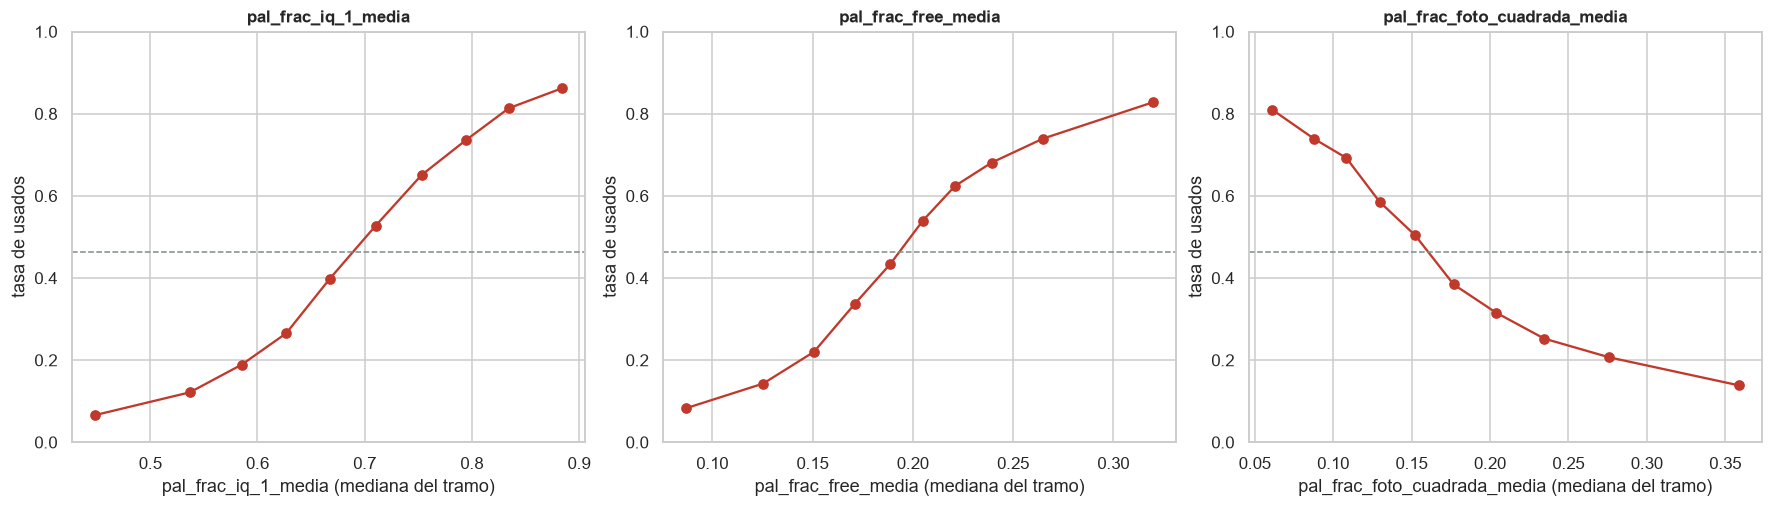

,tasa de usados por decil de pal_frac_iq_1_media
pal_frac_iq_1_media,
"(-0.001, 0.504]",0.066
"(0.504, 0.563]",0.122
"(0.563, 0.606]",0.189
"(0.606, 0.647]",0.265
"(0.647, 0.688]",0.398
"(0.688, 0.732]",0.527
"(0.732, 0.774]",0.651
"(0.774, 0.814]",0.736
"(0.814, 0.856]",0.813


In [23]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for columna, ax in zip(["pal_frac_iq_1_media", "pal_frac_free_media", "pal_frac_foto_cuadrada_media"], ejes):
    tasa_por_tramos(train, columna, ax)
plt.show()

por_decil = train.groupby(pd.qcut(train["pal_frac_iq_1_media"], 10, duplicates="drop"), observed=True)["y"].mean()
por_decil.round(3).to_frame("tasa de usados por decil de pal_frac_iq_1_media")

El resultado ordena muy bien los items. En el decil más bajo de `pal_frac_iq_1_media` hay 6,6% de usados y en el más alto 86,2%.

## 16. Ranking de variables y correlaciones

Para cada variable, la información mutua con el target y el accuracy (con 3 folds) de un árbol de profundidad 4 que solo ve esa variable.

In [24]:
NUMERICAS = [
    "initial_quantity", "sold_quantity", "available_quantity", "stock_desbalance",
    "log_price", "log_price_rel_categoria", "n_pictures", "n_attributes", "n_variations",
    "n_payment_methods", "warranty_len", "title_len", "title_frac_mayus",
    "dias_hasta_update", "duracion_dias", "hora_creacion", "pic_max_ancho",
    "seller_n_items", "seller_frac_free", "seller_frac_iq_1", "seller_frac_vendio",
    "seller_frac_warranty", "seller_frac_price_decimales", "seller_ratio_categorias",
    "cat_n_items", "cat_frac_free", "cat_frac_iq_1", "cat_frac_vendio",
    "seller_frac_repuso_stock", "seller_frac_foto_cuadrada", "seller_max_initial_quantity",
    "seller_items_mismo_minuto", "pal_frac_iq_1_media", "pal_frac_free_media",
    "pic0_aspecto", "pic_frac_cuadradas", "pic_lado_max", "title_n_digitos",
]
BOOLEANAS = [
    "iq_es_1", "vendio_algo", "automatic_relist", "accepts_mercadopago",
    "ship_free_shipping", "ship_local_pick_up", "price_con_decimales",
    "price_termina_en_9", "price_multiplo_100", "tiene_warranty", "tiene_video",
    "es_tienda_oficial", "t_nuevo", "t_usado", "t_estado_de_uso", "t_antiguo_coleccion",
    "w_fabrica", "w_plazo", "w_vendedor_o_estado",
]
X = train[NUMERICAS + BOOLEANAS].astype(float).fillna(-1)
arbol = DecisionTreeClassifier(max_depth=4, random_state=datos.SEED)
ranking = pd.DataFrame({
    "informacion_mutua": mutual_info_classif(X, train["y"], random_state=datos.SEED),
    "accuracy_arbol_1_variable": [cross_val_score(arbol, X[[c]], train["y"], cv=3).mean() for c in X.columns],
}, index=X.columns).sort_values("accuracy_arbol_1_variable", ascending=False)
ranking.head(20).round(3)

,informacion_mutua,accuracy_arbol_1_variable
seller_frac_free,0.189,0.774
seller_frac_iq_1,0.240,0.769
cat_frac_iq_1,0.211,0.759
pal_frac_iq_1_media,0.183,0.754
seller_max_initial_quantity,0.157,0.740
iq_es_1,0.182,0.732
initial_quantity,0.179,0.732
available_quantity,0.171,0.727
cat_frac_free,0.192,0.726
pal_frac_free_media,0.138,0.719


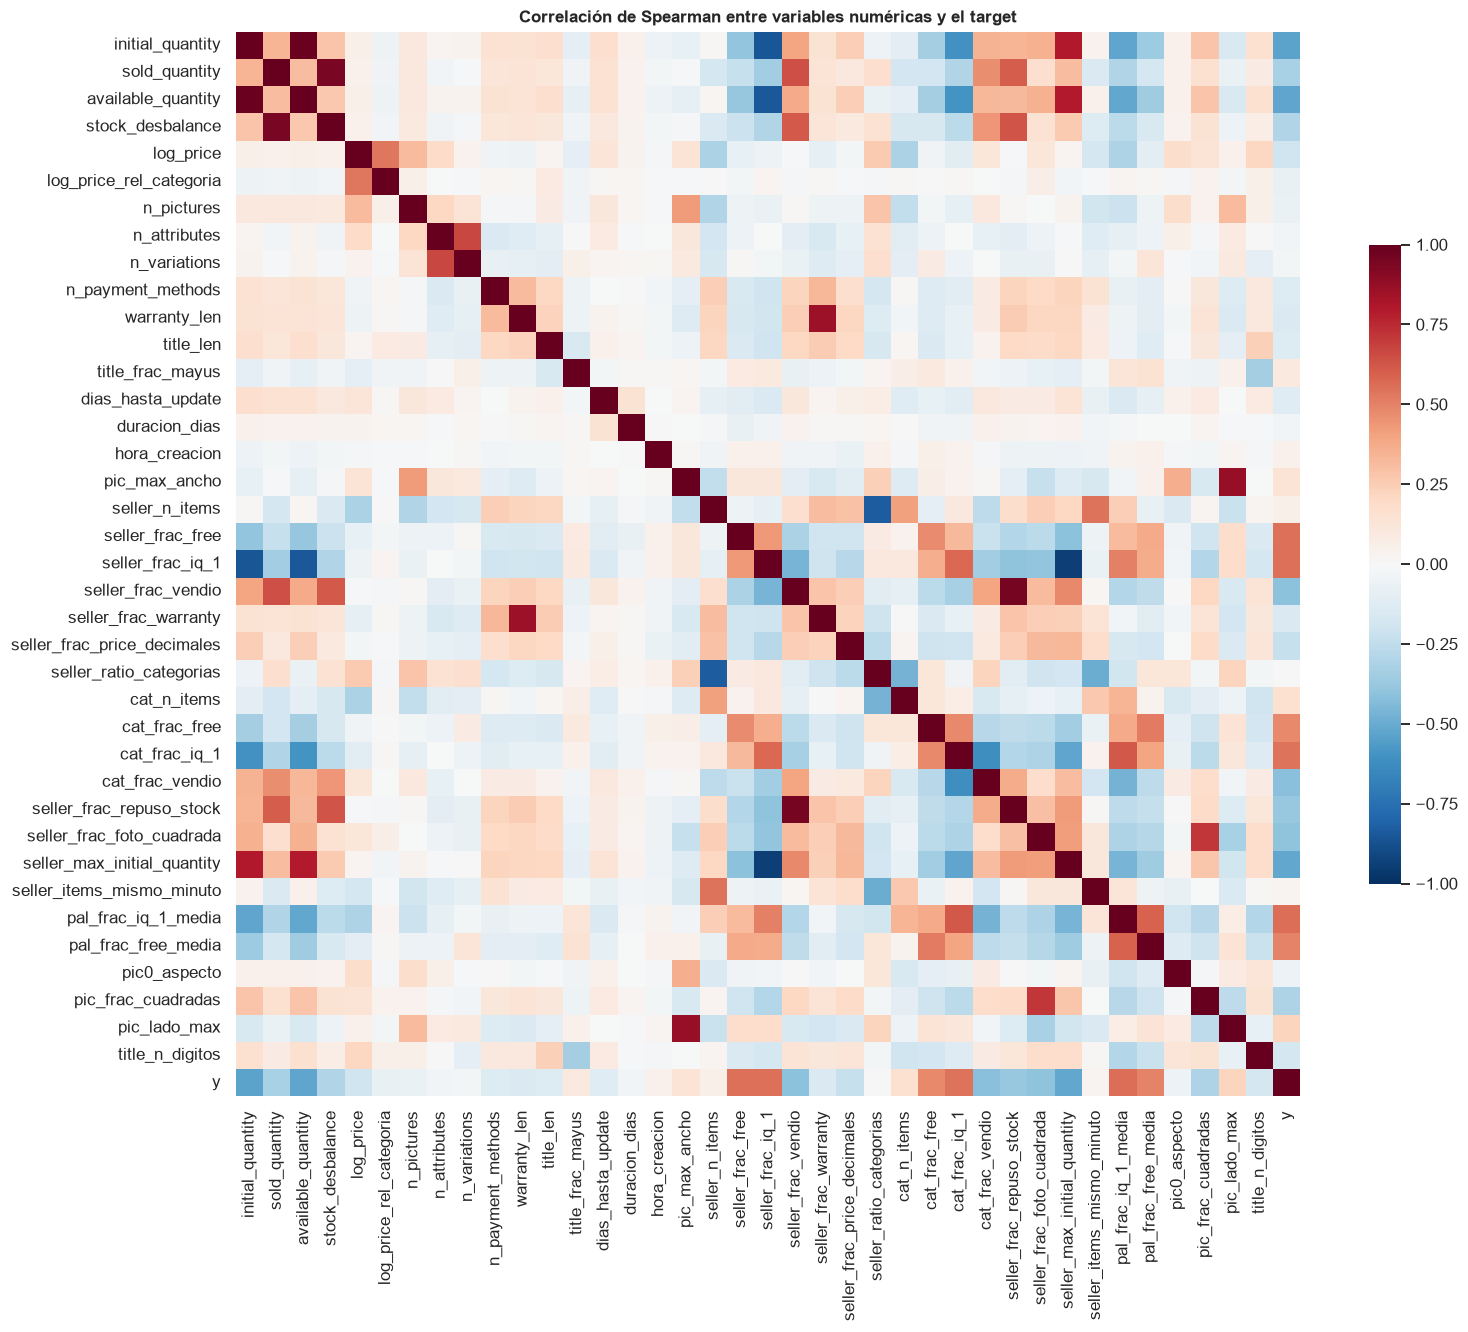

In [25]:
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(train[NUMERICAS + ["y"]].corr(method="spearman"), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            ax=ax, square=True, cbar_kws={"shrink": 0.6})
ax.set_title("Correlación de Spearman entre variables numéricas y el target")
plt.show()

Las variables individuales más predictivas son perfiles agregados del vendedor y de la categoría, por encima de cualquier atributo del item. Entre las del item lideran `initial_quantity` y `available_quantity`, y luego el precio.

En la matriz de correlación se ven tres cosas.

- `initial_quantity` y `available_quantity` son casi la misma variable (0.99). `sold_quantity` va por otro lado (0.34).
- `seller_frac_iq_1` está muy correlacionada con `initial_quantity` (-0.86), pero solo moderadamente con `seller_frac_free` (0.43). Ambas tienen la misma correlación con el target (0.55), así que capturan facetas distintas del vendedor particular y conviene mantener las dos.
- Las variables de "profesionalismo" (`seller_frac_warranty`, `seller_frac_price_decimales`, `n_payment_methods`) apuntan en la misma dirección pero se correlacionan poco entre sí (0.17 a 0.33). Son señales débiles e independientes que un modelo de árboles puede sumar.